In [160]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
import numpy as np
np.set_printoptions(suppress=True)
np.random.seed(1)
import random
random.seed(1)
import pandas as pd
pd.set_option("max_colwidth", 100)
pd.set_option("display.precision", 3)
from utilsforecast.plotting import plot_series as plot_series_utils
import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt
plt.style.use("ggplot")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
    "font.size": 11.5,
    "axes.titlesize": 14,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 9.5,
    "legend.title_fontsize": 11.5,
    "grid.alpha": 1.0,
})
import matplotlib as mpl
from cycler import cycler
mpl.rcParams['axes.prop_cycle'] = cycler(color=["#000000", "#000000"])
from fpppy.utils import plot_series

mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#2f2fff"], name="black_and_blue"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00"], name="black_and_orange"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#000000"], name="black"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#0072B2", "#D55E00"],
        name='black_and_2color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00", "#0072B2", "#009E73"],
        name='black_and_3color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00", "#0072B2", "#009E73", "#CC79A7"],
        name='black_and_4color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#D55E00", "#0072B2", "#009E73", "#CC79A7"],
        name='r_colors',
    ),
    force=True
)
import statsmodels.api as sm
from scipy.stats import pearsonr
from statsmodels.graphics.tsaplots import plot_acf

In [161]:
main_df = pd.read_csv('full_df.csv')

elevation

In [162]:
elevation = main_df["elevation"]

main_df_by_altitude = {
    "<400 m": main_df[elevation < 400].copy(),
    "400–<800 m": main_df[(elevation >= 400) & (elevation < 800)].copy(),
    "800–<1200 m": main_df[(elevation >= 800) & (elevation < 1200)].copy(),
    "≥1200 m": main_df[elevation >= 1200].copy(),
}

# Nord/sud selon la latitude ; les latitudes manquantes restent non classées.
main_df["north_south_region"] = pd.Series(pd.NA, index=main_df.index, dtype="string")
main_df.loc[main_df["latitude"] > 46.8, "north_south_region"] = "North"
main_df.loc[main_df["latitude"] <= 46.8, "north_south_region"] = "South"

geo zone 1 : 

In [163]:
main_df["north_south_region"] = np.where(
    main_df["latitude"] > 46.8,
    "North",
    "South",
)

zone 2 : NSEW   

In [164]:
stations_geo = main_df[
    ["station_abbr", "latitude", "longitude"]
].drop_duplicates("station_abbr").copy()

centre_lat = stations_geo["latitude"].mean()
centre_lon = stations_geo["longitude"].mean()

dx = (
    (stations_geo["longitude"] - centre_lon)
    * np.cos(np.deg2rad(centre_lat))
)
dy = stations_geo["latitude"] - centre_lat

stations_geo["geo_zone"] = np.select(
    [
        (dy >= 0) & (dy >= abs(dx)),
        (dy < 0) & (-dy >= abs(dx)),
        (dx < 0) & (abs(dx) > abs(dy)),
        (dx >= 0) & (dx > abs(dy)),
    ],
    ["North", "South", "West", "East"],
    default="East",
)

coordonnees_valides = stations_geo[["latitude", "longitude"]].notna().all(axis=1)
stations_geo.loc[~coordonnees_valides, "geo_zone"] = pd.NA

zones_par_station = stations_geo.set_index("station_abbr")["geo_zone"]
main_df["geo_zone"] = main_df["station_abbr"].map(zones_par_station)

distrib station number

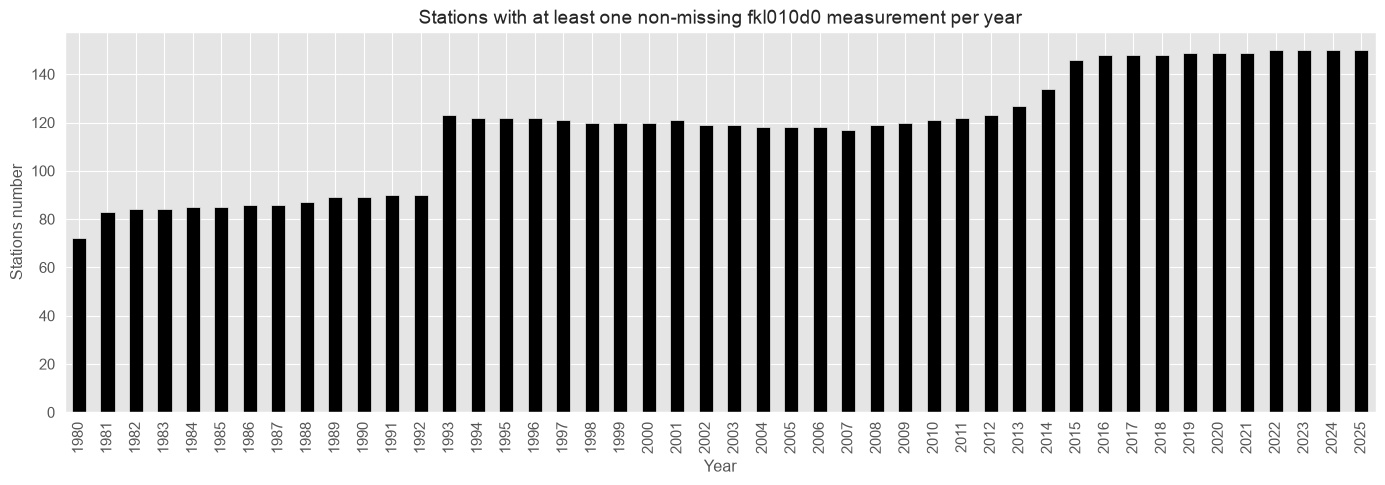

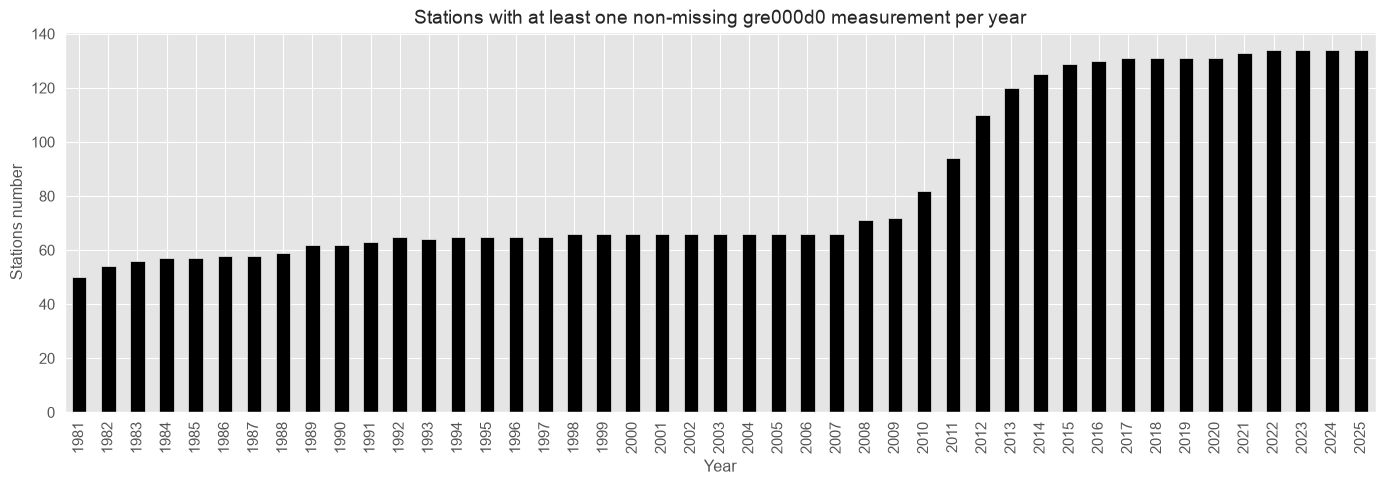

In [167]:
df = main_df.copy()
df["year"] = pd.to_datetime(df["reference_timestamp"], utc=True).dt.year

stations_par_annee = (
    df[df["fkl010d0"].notna()]
    .groupby("year")["station_abbr"]
    .nunique()
)

stations_par_annee.plot(kind="bar", figsize=(14, 5), xlabel="Year", ylabel="Stations number",
                        title="Stations with at least one non-missing fkl010d0 measurement per year")
plt.tight_layout()
plt.show()

# ----------------------------

df = main_df.copy()
df["year"] = pd.to_datetime(df["reference_timestamp"], utc=True).dt.year

stations_par_annee = (
    df[df["gre000d0"].notna()]
    .groupby("year")["station_abbr"]
    .nunique()
)

stations_par_annee.plot(kind="bar", figsize=(14, 5), xlabel="Year", ylabel="Stations number",
                        title="Stations with at least one non-missing gre000d0 measurement per year")
plt.tight_layout()
plt.show()

keep only the stable stations for : 

1980 -- 2025 
- fkl010d0 - keep only the stable station on the period give the number in a dataset named: 'df_stable_wind_1980_2025'
- gre000d0 - keep only the stable station on the period give the number in a dataset named: 'df_stable_solar_1980_2025'
- find the stations and its number in a dataset 'df_stable_1980_2025' with the stations having a value for (fkl010d0 & gre000d0)

2015 -- 2024
- fkl010d0 - keep only the stable station on the period give the number in a dataset named: 'df_stable_wind_2015_2025'
- gre000d0 - keep only the stable station on the period give the number in a dataset named: 'df_stable_wind_2015_2025'
- find the stations and its number in a dataset 'df_stable_2015_2025' with the stations having a value for (fkl010d0 & gre000d0)

In [120]:
# Recharger les données complètes, sans le filtre de cohorte appliqué à main_df
df_all = pd.read_csv("full_df.csv")

# Remplacer par NaN les mesures hors des plages retenues
valid_ranges = {
    "fkl010d0": (0, 40),
    "fkl010m0": (0, 30),
    "gre000d0": (0, 500),
    "gre000m0": (0, 400),
}

for measure, (minimum, maximum) in valid_ranges.items():
    df_all[measure] = df_all[measure].where(
        df_all[measure].between(minimum, maximum)
    )

# Extraire l'année de chaque observation
df_all["year"] = pd.to_datetime(
    df_all["reference_timestamp"], utc=True, errors="raise"
).dt.year


def stable_stations(data, measure, start_year, end_year):
    """Stations ayant au moins une mesure valide chaque année."""
    years = range(start_year, end_year + 1)

    has_data_by_year = (
        data.loc[data["year"].between(start_year, end_year)]
        .groupby(["station_abbr", "year"])[measure]
        .agg(lambda values: values.notna().any())
        .unstack("year", fill_value=False)
        .reindex(columns=years, fill_value=False)
    )

    return has_data_by_year.index[has_data_by_year.all(axis=1)]


def keep_stations_in_period(data, stations, start_year, end_year):
    mask = (
        data["station_abbr"].isin(stations)
        & data["year"].between(start_year, end_year)
    )
    return data.loc[mask].copy()


# Cohorte de référence : vent en 1980 ET radiation solaire en 1981
wind_stations_1980 = set(
    df_all.loc[
        df_all["year"].eq(1980) & df_all["fkl010d0"].notna(),
        "station_abbr",
    ].dropna()
)

solar_stations_1981 = set(
    df_all.loc[
        df_all["year"].eq(1981) & df_all["gre000d0"].notna(),
        "station_abbr",
    ].dropna()
)

stations_to_keep = wind_stations_1980 & solar_stations_1981

# Cohorte de référence, conservée séparément du jeu complet
df_baseline = df_all[
    df_all["station_abbr"].isin(stations_to_keep)
].copy()

print("Stations avec du vent en 1980 :", len(wind_stations_1980))
print("Stations avec du solaire en 1981 :", len(solar_stations_1981))
print("Stations dans la cohorte de référence :", len(stations_to_keep))


# 1980–2025 : stabilité calculée dans la cohorte de référence
wind_stations_1980_2025 = stable_stations(
    df_baseline, "fkl010d0", 1980, 2025
)
solar_stations_1980_2025 = stable_stations(
    df_baseline, "gre000d0", 1981, 2025
)

both_stations_1980_2025 = wind_stations_1980_2025.intersection(
    solar_stations_1980_2025
)

df_stable_wind_1980_2025 = keep_stations_in_period(
    df_baseline, wind_stations_1980_2025, 1980, 2025
)
df_stable_solar_1980_2025 = keep_stations_in_period(
    df_baseline, solar_stations_1980_2025, 1981, 2025
)
df_stable_1980_2025 = keep_stations_in_period(
    df_baseline, both_stations_1980_2025, 1980, 2025
)


# Comptes en 2015 : toutes les stations du jeu complet
stations_wind_2015 = df_all.loc[
    df_all["year"].eq(2015) & df_all["fkl010d0"].notna(),
    "station_abbr",
].nunique()

stations_solar_2015 = df_all.loc[
    df_all["year"].eq(2015) & df_all["gre000d0"].notna(),
    "station_abbr",
].nunique()


# 2015–2025 : stabilité calculée sur toutes les stations
wind_stations_2015_2025 = stable_stations(
    df_all, "fkl010d0", 2015, 2025
)
solar_stations_2015_2025 = stable_stations(
    df_all, "gre000d0", 2015, 2025
)

both_stations_2015_2025 = wind_stations_2015_2025.intersection(
    solar_stations_2015_2025
)

df_stable_wind_2015_2025 = keep_stations_in_period(
    df_all, wind_stations_2015_2025, 2015, 2025
)
df_stable_solar_2015_2025 = keep_stations_in_period(
    df_all, solar_stations_2015_2025, 2015, 2025
)
df_stable_2015_2025 = keep_stations_in_period(
    df_all, both_stations_2015_2025, 2015, 2025
)


# Résultats
print("\n2015 — toutes les stations")
print("Stations avec du vent :", stations_wind_2015)
print("Stations avec de la radiation solaire :", stations_solar_2015)

print("\n1980–2025 — cohorte de référence")
print("Stations stables pour le vent :", len(wind_stations_1980_2025))
print("Stations stables pour le solaire :", len(solar_stations_1980_2025))
print("Stations stables pour les deux variables :", len(both_stations_1980_2025))

print("\n2015–2025 — toutes les stations")
print("Stations stables pour le vent :", len(wind_stations_2015_2025))
print("Stations stables pour le solaire :", len(solar_stations_2015_2025))
print("Stations stables pour les deux variables :", len(both_stations_2015_2025))

Stations avec du vent en 1980 : 72
Stations avec du solaire en 1981 : 50
Stations dans la cohorte de référence : 42

2015 — toutes les stations
Stations avec du vent : 146
Stations avec de la radiation solaire : 129

1980–2025 — cohorte de référence
Stations stables pour le vent : 42
Stations stables pour le solaire : 42
Stations stables pour les deux variables : 42

2015–2025 — toutes les stations
Stations stables pour le vent : 145
Stations stables pour le solaire : 129
Stations stables pour les deux variables : 123


# Graphs sections

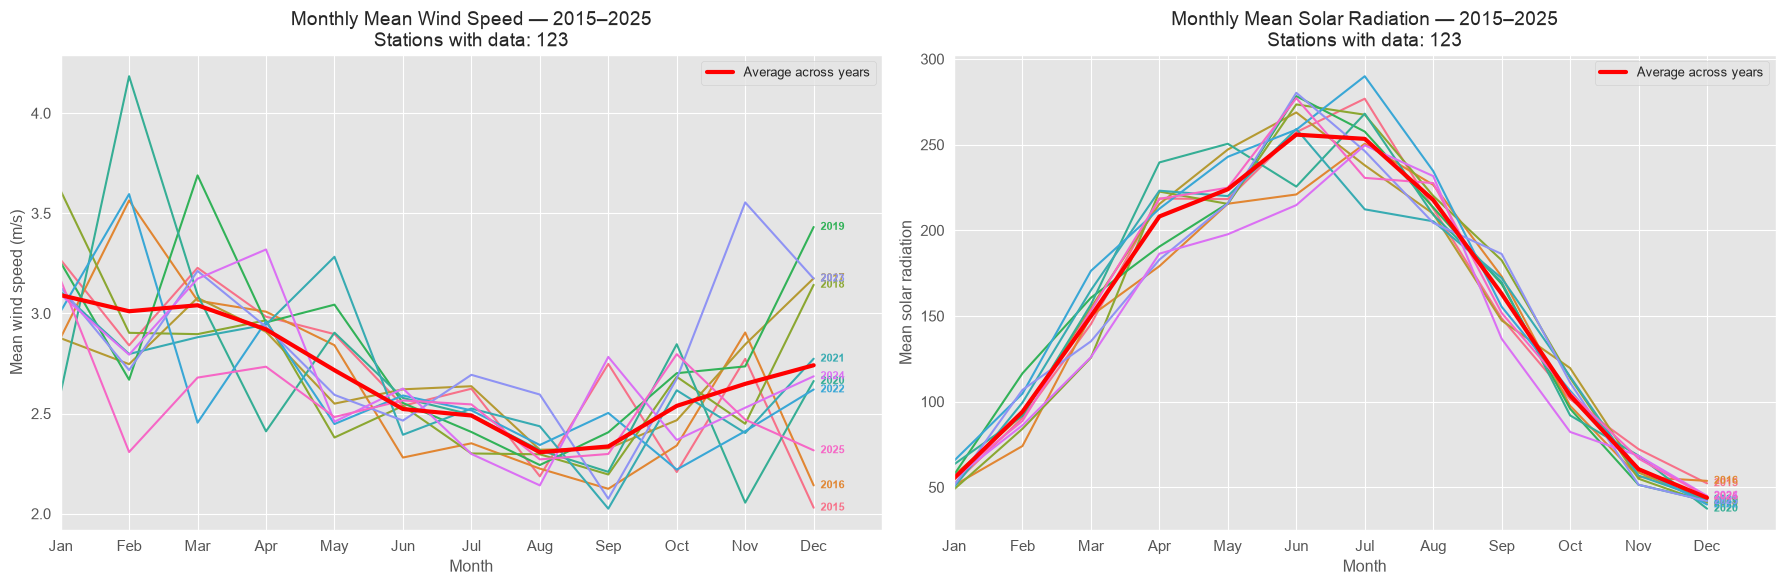

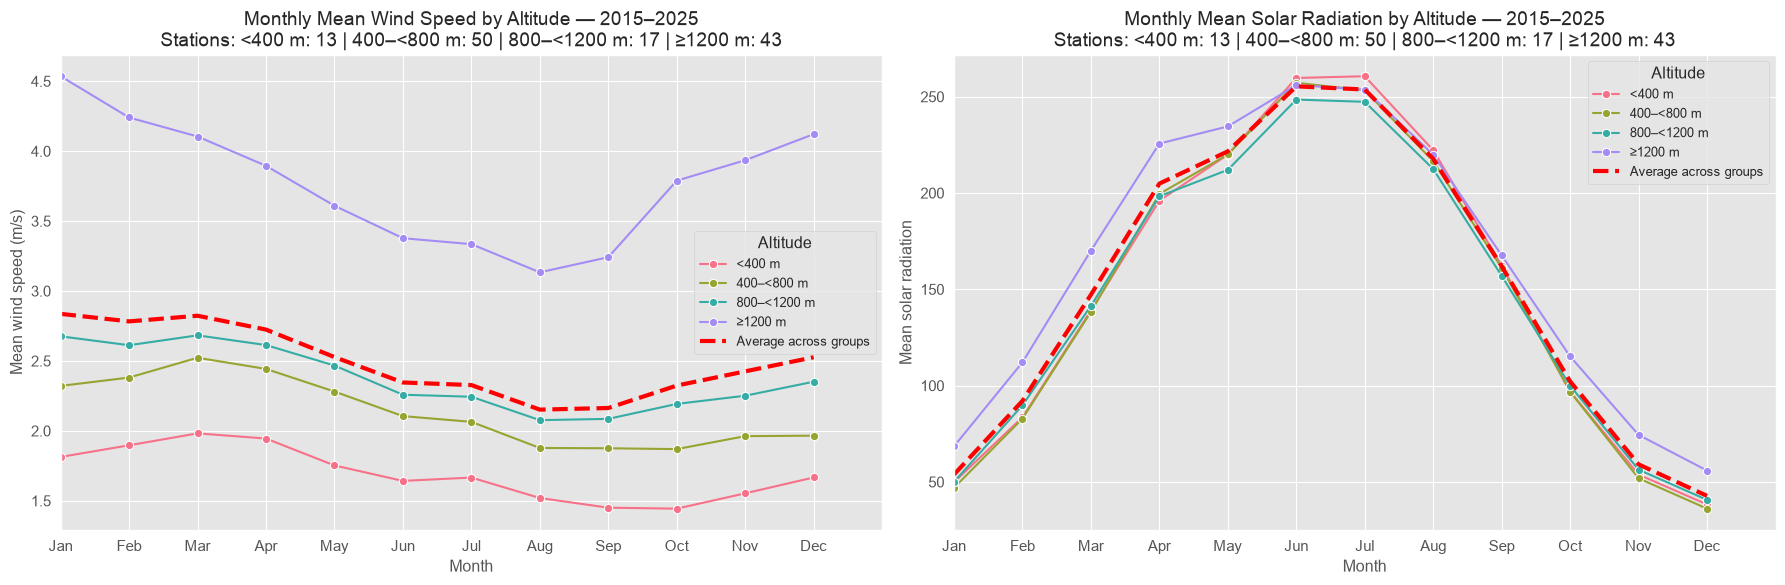

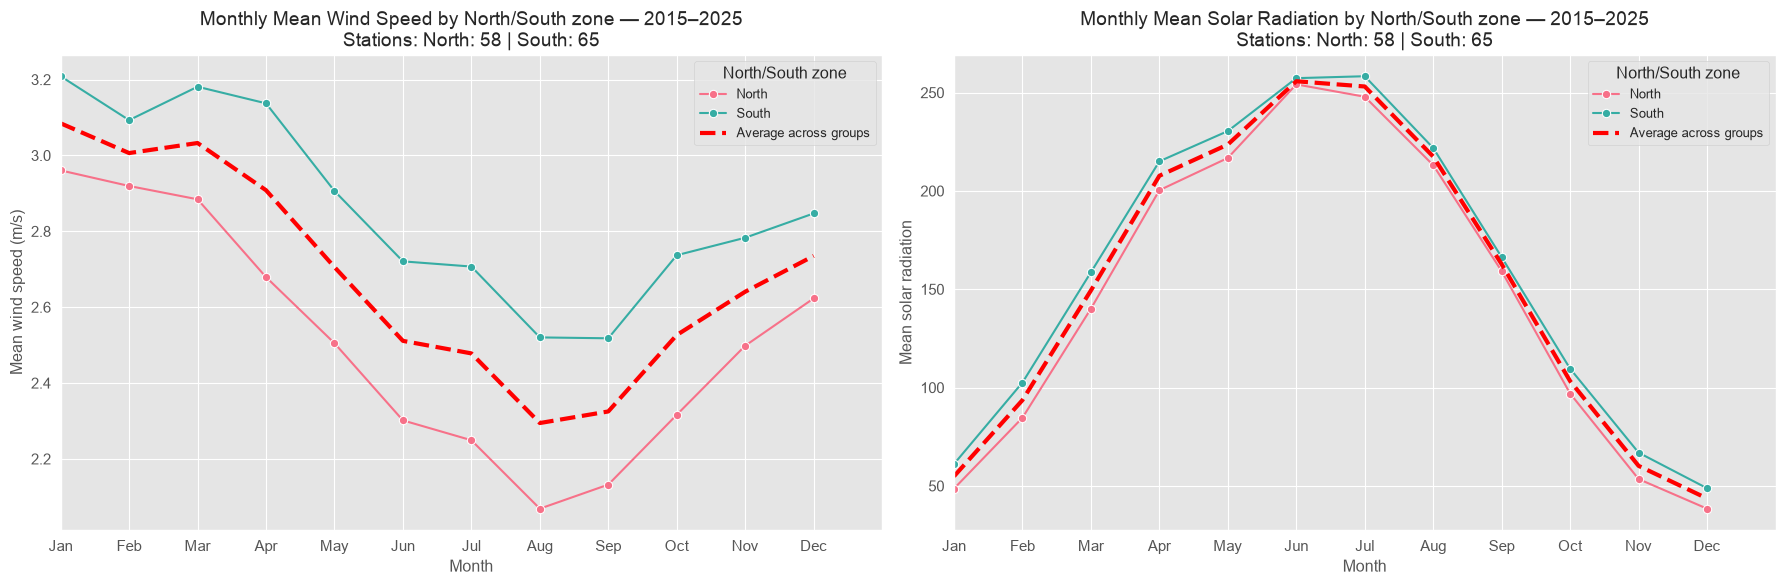

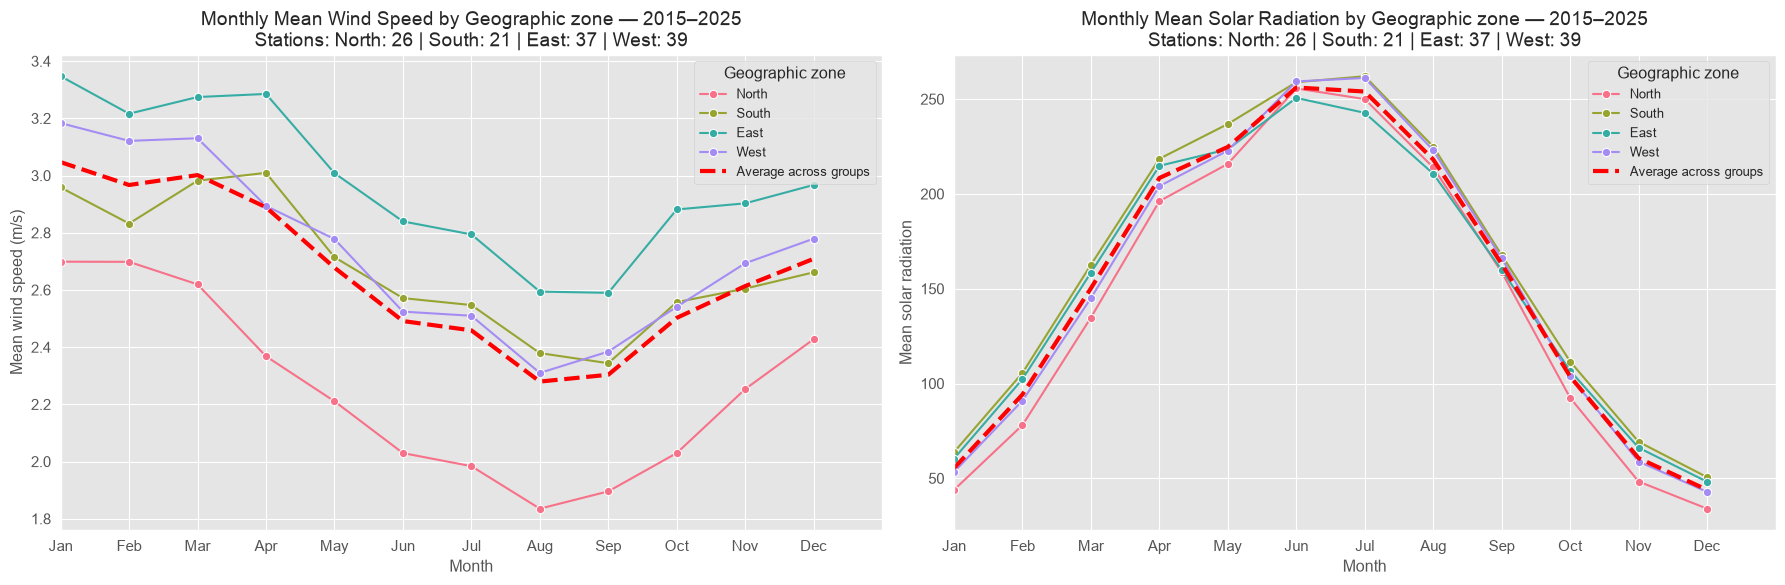

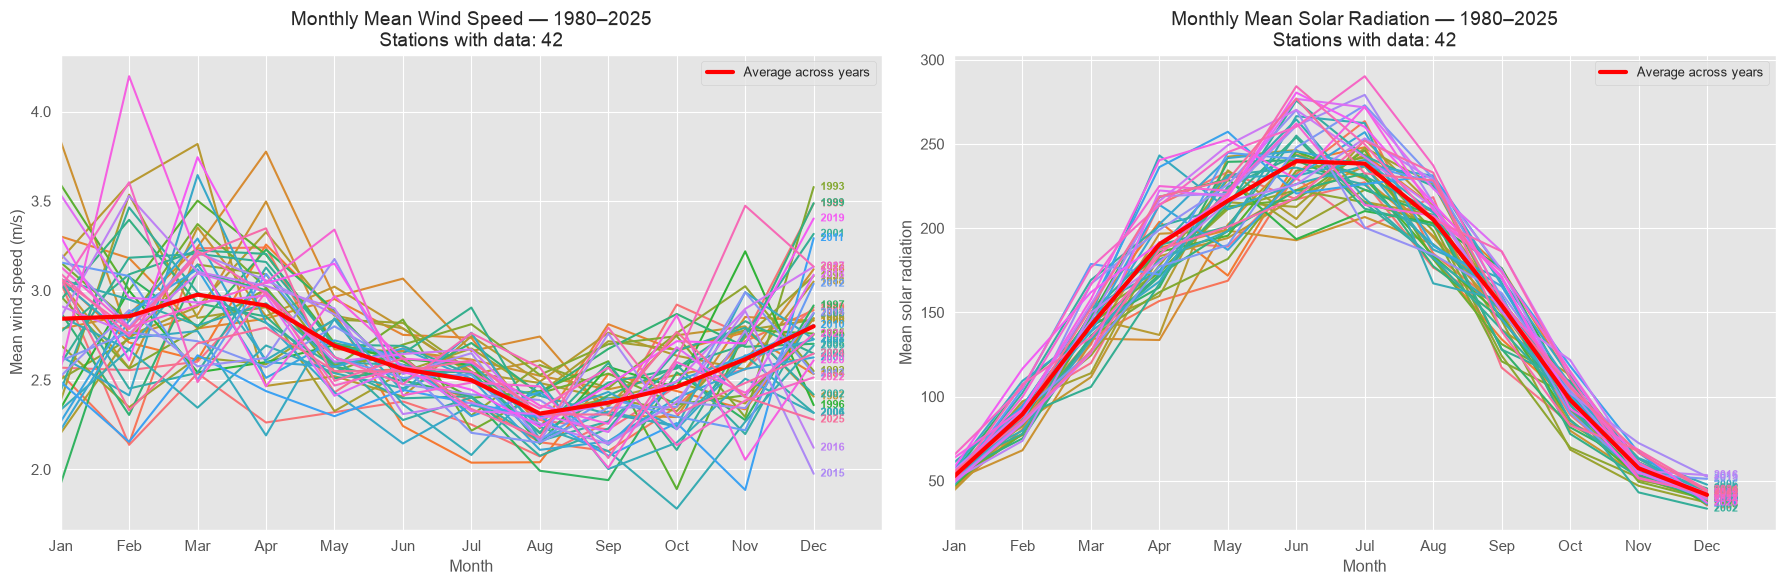

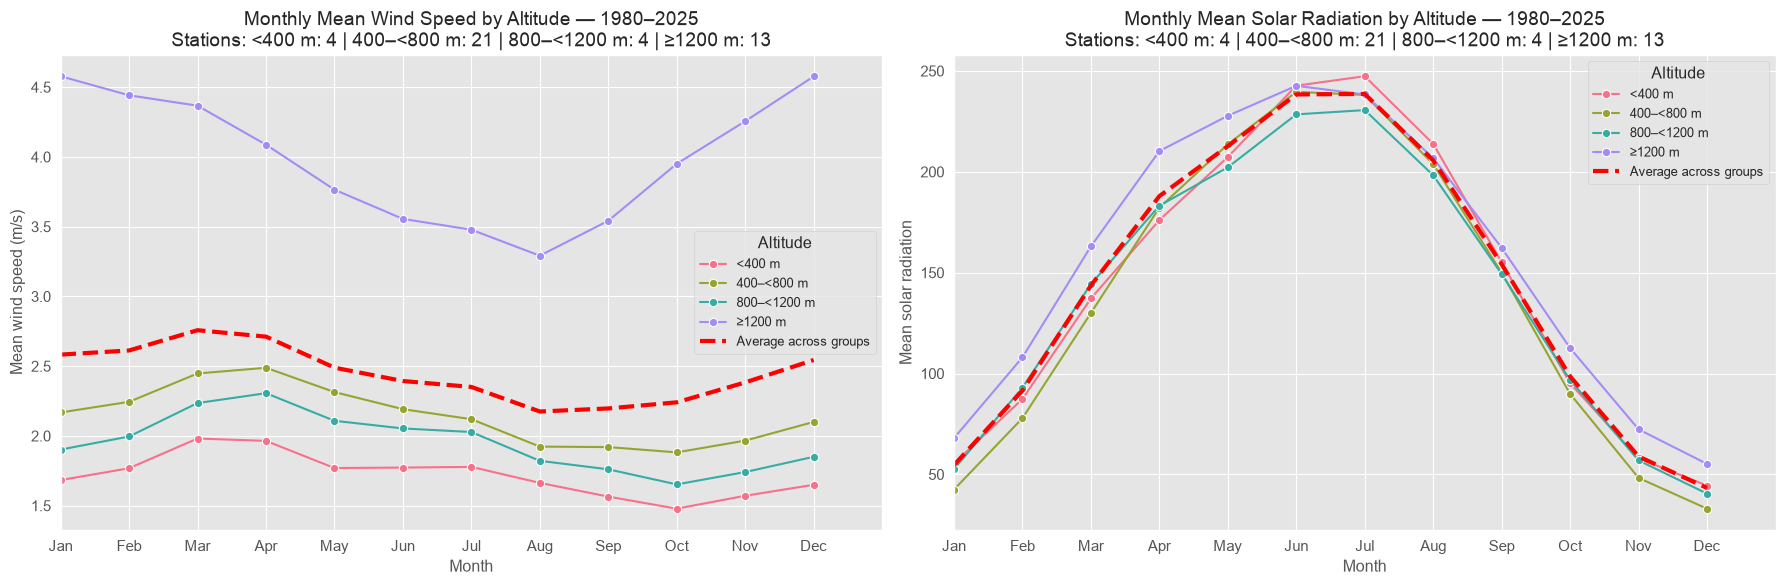

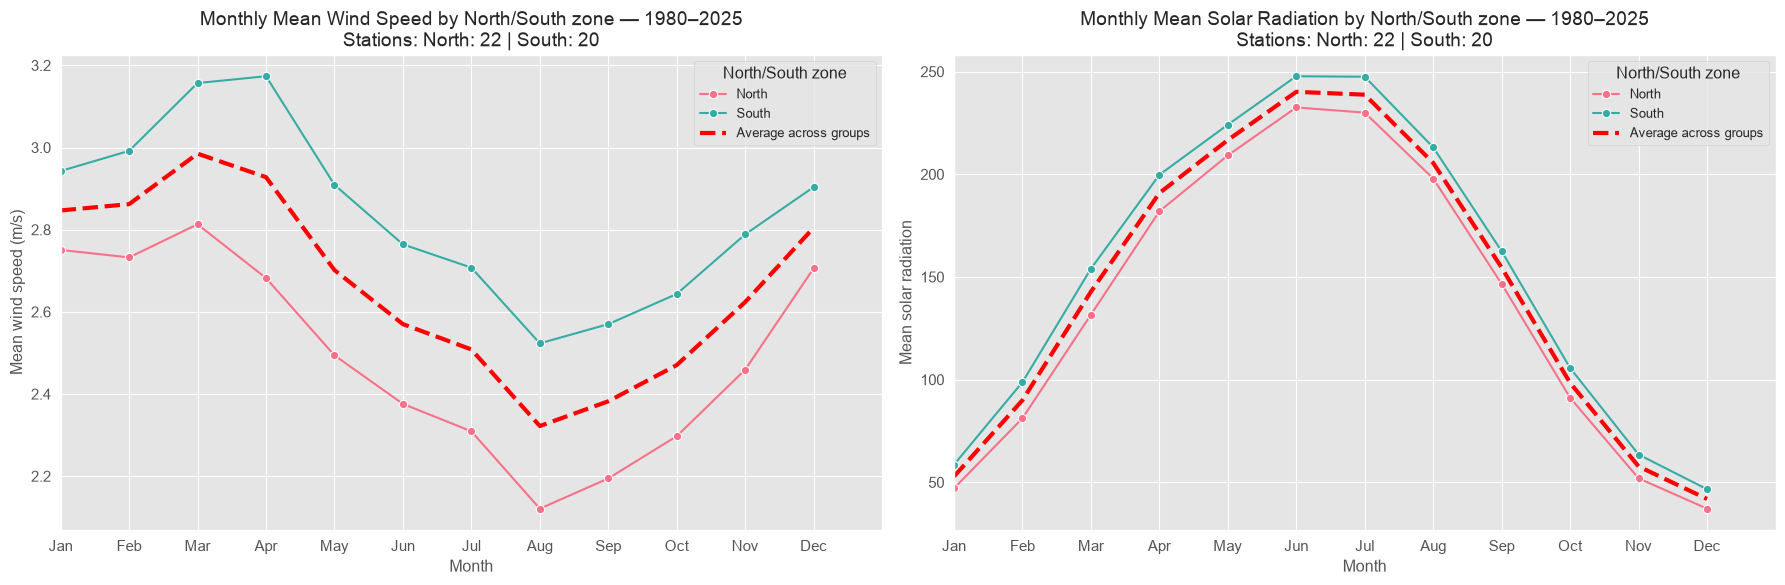

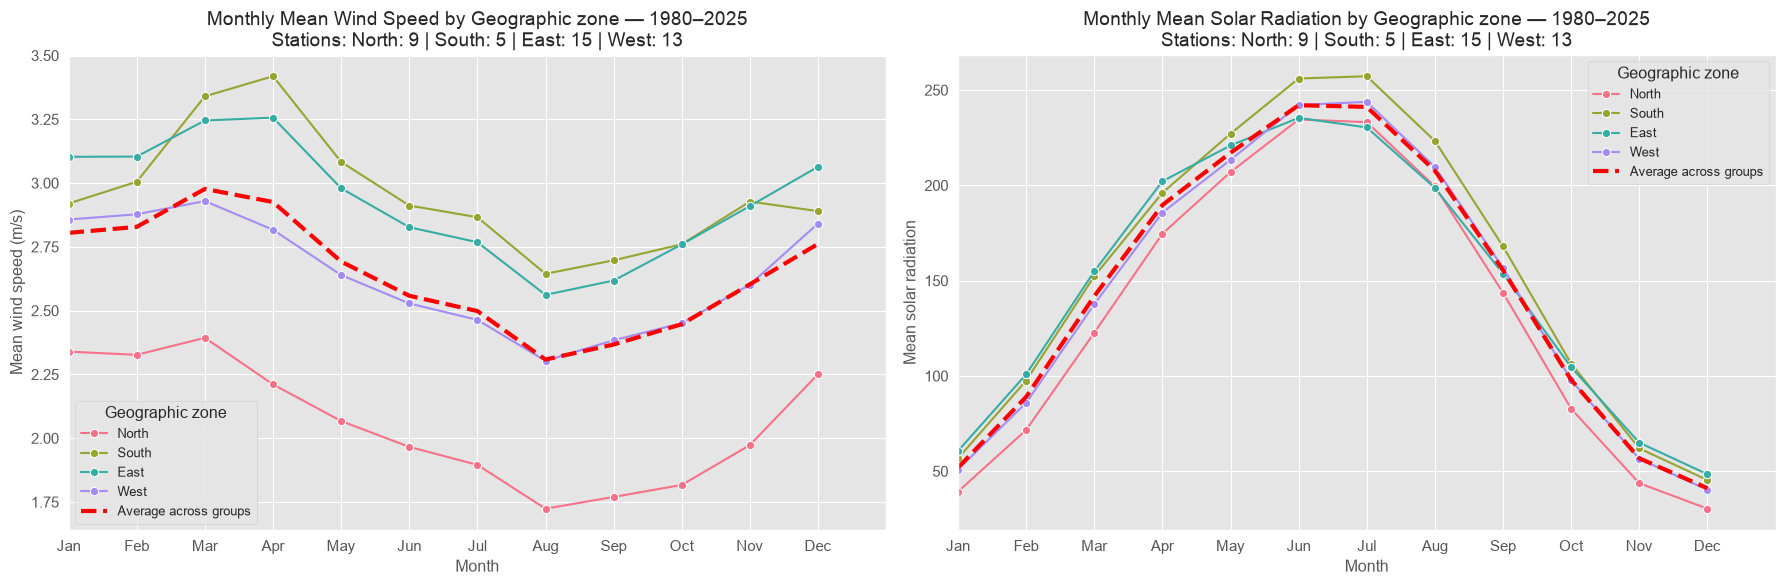

In [123]:
datasets = {
    "2015–2025": df_stable_2015_2025,
    "1980–2025": df_stable_1980_2025,
}

# Les graphiques quotidiens sont retirés
frequencies = {
    "Monthly": {"wind": "fkl010m0", "solar": "gre000m0"},
}

measure_info = {
    "wind": ("Mean Wind Speed", "Mean wind speed (m/s)"),
    "solar": ("Mean Solar Radiation", "Mean solar radiation"),
}

altitude_order = ["<400 m", "400–<800 m", "800–<1200 m", "≥1200 m"]
north_south_order = ["North", "South"]
geo_order = ["North", "South", "East", "West"]

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

# Préparer les zones géographiques à partir des coordonnées de toutes les stations
stations_geo = (
    df_all[["station_abbr", "latitude", "longitude"]]
    .drop_duplicates("station_abbr")
    .copy()
)

centre_lat = stations_geo["latitude"].mean()
centre_lon = stations_geo["longitude"].mean()

dx = (
    (stations_geo["longitude"] - centre_lon)
    * np.cos(np.deg2rad(centre_lat))
)
dy = stations_geo["latitude"] - centre_lat

stations_geo["geo_zone"] = np.select(
    [
        (dy >= 0) & (dy >= abs(dx)),
        (dy < 0) & (-dy >= abs(dx)),
        (dx < 0) & (abs(dx) > abs(dy)),
        (dx >= 0) & (dx > abs(dy)),
    ],
    ["North", "South", "West", "East"],
    default="East",
)

coordonnees_valides = stations_geo[["latitude", "longitude"]].notna().all(axis=1)
stations_geo.loc[~coordonnees_valides, "geo_zone"] = pd.NA

geo_zone_by_station = stations_geo.set_index("station_abbr")["geo_zone"]


def prepare_plot_data(source):
    data = source.copy()

    data["Date"] = pd.to_datetime(
        data["reference_timestamp"], utc=True, errors="raise"
    )
    data["Year"] = data["Date"].dt.year
    data["Month_num"] = data["Date"].dt.month

    # Nord/Sud selon la latitude
    data["north_south_region"] = np.where(
        data["latitude"] > 46.8,
        "North",
        "South",
    )

    # Zone géographique calculée à partir des coordonnées des stations
    data["geo_zone"] = data["station_abbr"].map(geo_zone_by_station)

    # Classes d'altitude
    data["altitude_class"] = pd.cut(
        pd.to_numeric(data["elevation"], errors="coerce"),
        bins=[-float("inf"), 400, 800, 1200, float("inf")],
        labels=altitude_order,
        right=False,
    )

    return data


def format_month_axis(ax, ylabel):
    ax.set(
        xlabel="Month",
        ylabel=ylabel,
        xticks=range(1, 13),
        xticklabels=month_labels,
        xlim=(1, 13),
    )


def plot_overall(data, period, frequency):
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    for ax, measure in zip(axes, ["wind", "solar"]):
        variable = frequencies[frequency][measure]
        title, ylabel = measure_info[measure]

        available = data.loc[
            data[variable].notna() & data["station_abbr"].notna()
        ].copy()
        station_count = available["station_abbr"].nunique()

        monthly_by_year = (
            available.groupby(["Year", "Month_num"], as_index=False)
            .agg(mean_value=(variable, "mean"))
        )

        years = sorted(monthly_by_year["Year"].unique())
        colors = dict(
            zip(years, sns.color_palette("husl", n_colors=len(years)))
        )

        sns.lineplot(
            data=monthly_by_year,
            x="Month_num",
            y="mean_value",
            hue="Year",
            hue_order=years,
            palette=colors,
            legend=False,
            ax=ax,
        )

        average = monthly_by_year.groupby("Month_num")["mean_value"].mean()
        ax.plot(
            average.index,
            average.values,
            color="red",
            linewidth=3,
            label="Average across years",
        )

        ax.set_title(
            f"{frequency} {title} — {period}\n"
            f"Stations with data: {station_count}"
        )
        format_month_axis(ax, ylabel)

        for year, subset in monthly_by_year.groupby("Year", sort=True):
            last_point = subset.sort_values("Month_num").iloc[-1]
            ax.text(
                last_point["Month_num"] + 0.1,
                last_point["mean_value"],
                str(year),
                ha="left",
                va="center",
                fontsize=8,
                weight="bold",
                color=colors[year],
            )

        ax.legend()

    fig.tight_layout()
    plt.show()


def plot_by_group(data, period, frequency, group_column, group_order, group_title):
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    for ax, measure in zip(axes, ["wind", "solar"]):
        variable = frequencies[frequency][measure]
        title, ylabel = measure_info[measure]

        available = data.loc[
            data[variable].notna()
            & data[group_column].notna()
            & data["station_abbr"].notna()
        ].copy()

        station_counts = (
            available.groupby(group_column, observed=True)["station_abbr"]
            .nunique()
            .to_dict()
        )

        # Moyenne des stations par année, mois et catégorie,
        # puis moyenne des profils annuels pour chaque mois.
        annual_means = (
            available.groupby(
                [group_column, "Year", "Month_num"],
                observed=True,
                as_index=False,
            )
            .agg(mean_value=(variable, "mean"))
        )

        profiles = (
            annual_means.groupby(
                [group_column, "Month_num"],
                observed=True,
                as_index=False,
            )
            .agg(mean_value=("mean_value", "mean"))
        )

        present_groups = [
            group
            for group in group_order
            if group in profiles[group_column].dropna().unique()
        ]

        colors = dict(
            zip(
                present_groups,
                sns.color_palette("husl", n_colors=len(present_groups)),
            )
        )

        sns.lineplot(
            data=profiles,
            x="Month_num",
            y="mean_value",
            hue=group_column,
            hue_order=present_groups,
            palette=colors,
            marker="o",
            ax=ax,
        )

        average = profiles.groupby("Month_num")["mean_value"].mean()
        ax.plot(
            average.index,
            average.values,
            color="red",
            linewidth=3,
            linestyle="--",
            label="Average across groups",
        )

        counts = " | ".join(
            f"{group}: {station_counts.get(group, 0)}"
            for group in group_order
        )

        ax.set_title(
            f"{frequency} {title} by {group_title} — {period}\n"
            f"Stations: {counts}"
        )
        format_month_axis(ax, ylabel)
        ax.legend(title=group_title)

    fig.tight_layout()
    plt.show()


for period, source in datasets.items():
    plot_data = prepare_plot_data(source)
    frequency = "Monthly"

    # Vue générale : une ligne par année
    plot_overall(plot_data, period, frequency)

    # Graphiques par classe d'altitude
    plot_by_group(
        plot_data,
        period,
        frequency,
        group_column="altitude_class",
        group_order=altitude_order,
        group_title="Altitude",
    )

    # Graphiques par zone Nord/Sud
    plot_by_group(
        plot_data,
        period,
        frequency,
        group_column="north_south_region",
        group_order=north_south_order,
        group_title="North/South zone",
    )

    # Graphiques par zone géographique
    plot_by_group(
        plot_data,
        period,
        frequency,
        group_column="geo_zone",
        group_order=geo_order,
        group_title="Geographic zone",
    )

# MAPS part

In [35]:
import geopandas as gpd

fichier = "map/swissBOUNDARIES3D_1_5_LV95_LN02.gpkg"

layers = gpd.list_layers(fichier)

print(layers)

                name   geometry_type
0  tlm_hoheitsgrenze    LineString Z
1  tlm_hoheitsgebiet  MultiPolygon Z
2  tlm_bezirksgebiet  MultiPolygon Z
3   tlm_landesgebiet  MultiPolygon Z
4  tlm_kantonsgebiet  MultiPolygon Z


In [34]:
carte = gpd.read_file(fichier)
print(carte.columns)  

Index(['uuid', 'datum_aenderung', 'datum_erstellung', 'erstellung_jahr',
       'erstellung_monat', 'grund_aenderung', 'herkunft', 'herkunft_jahr',
       'herkunft_monat', 'revision_jahr', 'revision_monat',
       'revision_qualitaet', 'objektart', 'icc', 'typ', 'geometry'],
      dtype='str')


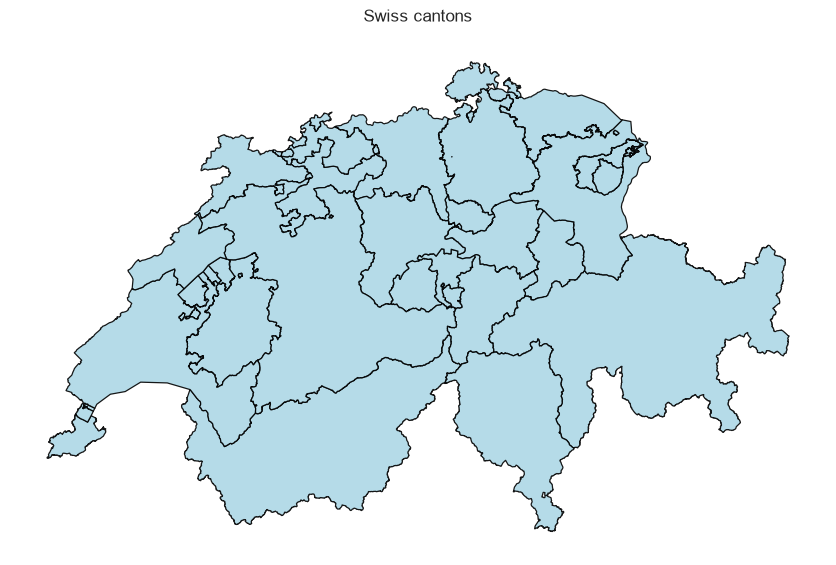

In [73]:
cantons = gpd.read_file(fichier, layer="tlm_kantonsgebiet")

ax = cantons.plot(
    column="name",          # une couleur par canton
    categorical=True,
    #cmap="blue",        # palette de couleurs
    color="lightblue",
    legend=True,
    figsize=(10, 20),
    edgecolor="black",      # couleur des limites
    linewidth=0.9,          # épaisseur des limites
    alpha=0.9,             # opacité
)

ax.set_title("Swiss cantons", fontsize=12, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()


In [79]:
df_stable_2015_2024.columns

Index(['station_abbr', 'reference_timestamp', 'fkl010d0', 'fkl010m0',
       'gre000d0', 'gre000m0', 'latitude', 'longitude', 'elevation',
       'north_south_region', 'geo_zone', 'year'],
      dtype='str')

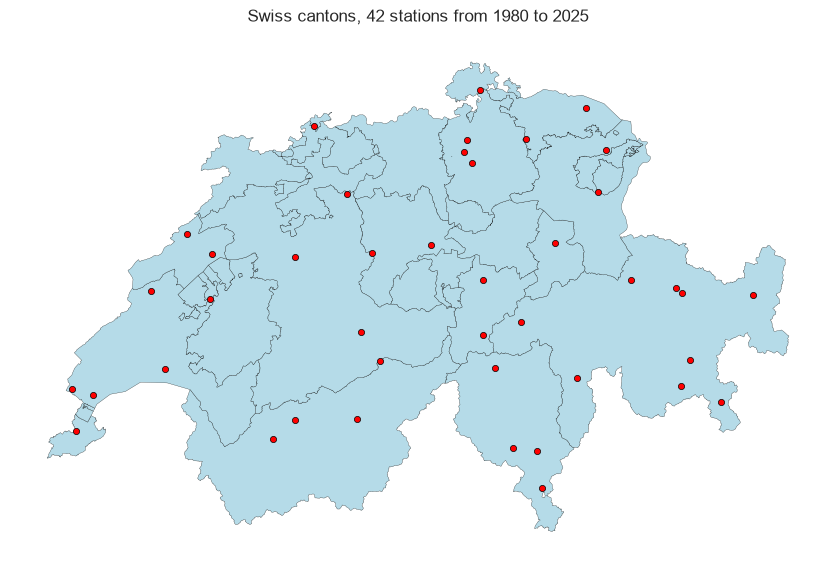

In [ ]:
stations_location_1 = df_stable_2015_2024[["station_abbr", "latitude", "longitude"]].drop_duplicates("station_abbr")

points = gpd.GeoDataFrame(
    stations_location_1,
    geometry=gpd.points_from_xy(stations_location_1["longitude"], stations_location_1["latitude"]),
    crs="EPSG:4326",  # coordonnées longitude/latitude
).to_crs(cantons.crs)  # même projection que la carte

ax = cantons.plot(
    column="name",          # une couleur par canton
    categorical=True,
    #cmap="blue",        # palette de couleurs
    color="lightblue",
    legend=True,
    figsize=(10, 20),
    edgecolor="black",      # couleur des limites
    linewidth=0.2,          # épaisseur des limites
    alpha=0.9,             # opacité
)

points.plot(ax=ax, color="red", markersize=20, edgecolor="black")

ax.set_title("Swiss cantons, 42 stations from 1980 to 2025", fontsize=12, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

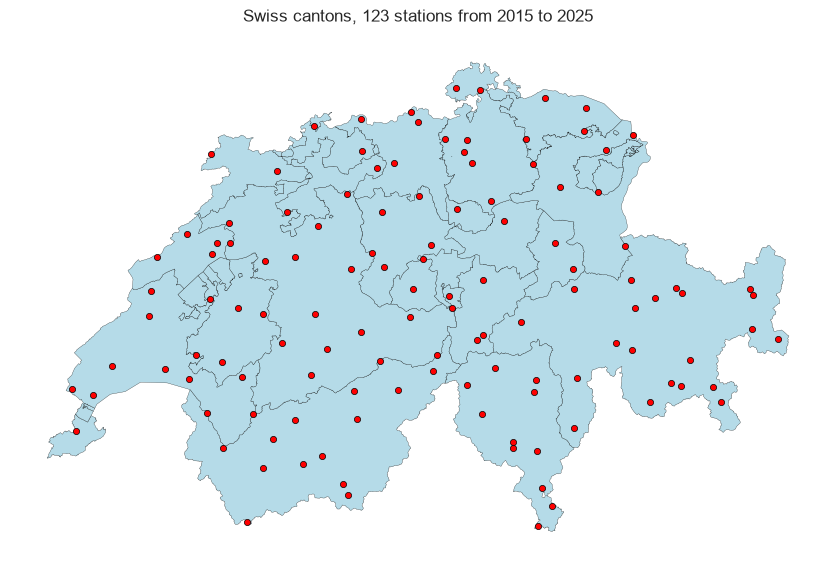

In [ ]:
stations_location_2 = df_stable_2015_2025[["station_abbr", "latitude", "longitude"]].drop_duplicates("station_abbr")

points = gpd.GeoDataFrame(
    stations_location_2,
    geometry=gpd.points_from_xy(stations_location_2["longitude"], stations_location_2["latitude"]),
    crs="EPSG:4326",  # coordonnées longitude/latitude
).to_crs(cantons.crs)  # même projection que la carte

ax = cantons.plot(
    column="name",          # une couleur par canton
    categorical=True,
    #cmap="blue",        # palette de couleurs
    color="lightblue",
    legend=True,
    figsize=(10, 20),
    edgecolor="black",      # couleur des limites
    linewidth=0.2,          # épaisseur des limites
    alpha=0.9,             # opacité
)

points.plot(ax=ax, color="red", markersize=20, edgecolor="black")

ax.set_title("Swiss cantons, 123 stations from 2015 to 2025", fontsize=12, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Merge two principal graphs :

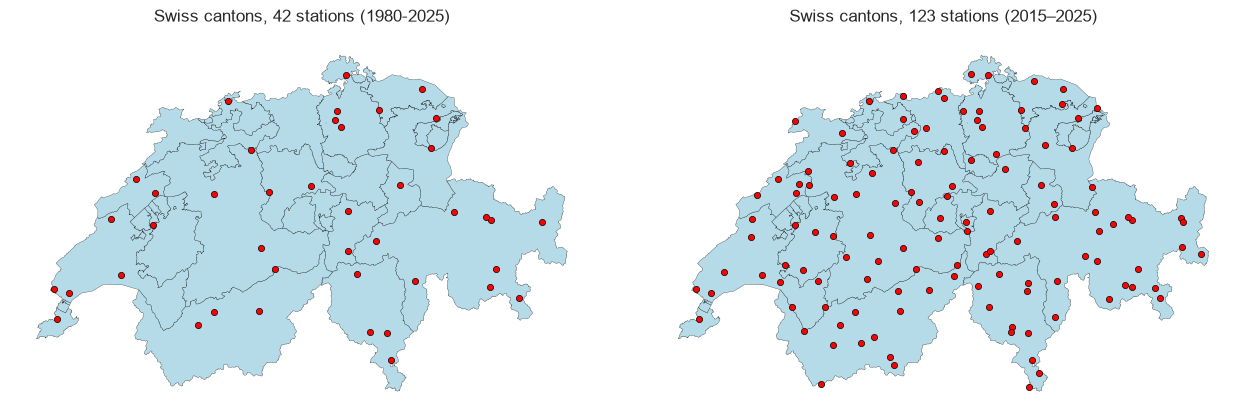

In [150]:
import geopandas as gpd
import matplotlib.pyplot as plt


def creer_points(df):
    stations = (
        df[["station_abbr", "latitude", "longitude"]]
        .dropna(subset=["station_abbr", "latitude", "longitude"])
        .drop_duplicates(subset="station_abbr")
    )

    return gpd.GeoDataFrame(
        stations,
        geometry=gpd.points_from_xy(
            stations["longitude"],
            stations["latitude"],
        ),
        crs="EPSG:4326",
    ).to_crs(cantons.crs)


points_1980_2025 = creer_points(df_stable_1980_2025)
points_2015_2025 = creer_points(df_stable_2015_2025)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

cartes = [
    (axes[0], points_1980_2025, "1980-2025"),
    (axes[1], points_2015_2025, "2015–2025"),
]

for ax, points, periode in cartes:
    cantons.plot(
        ax=ax,
        color="lightblue",
        edgecolor="black",
        linewidth=0.2,
        alpha=0.9,
    )

    points.plot(
        ax=ax,
        color="red",
        markersize=20,
        edgecolor="black",
    )

    ax.set_title(
        f"Swiss cantons, {len(points)} stations ({periode})",
        fontsize=12,
        pad=12,
    )
    ax.set_axis_off()

plt.tight_layout()
plt.show()

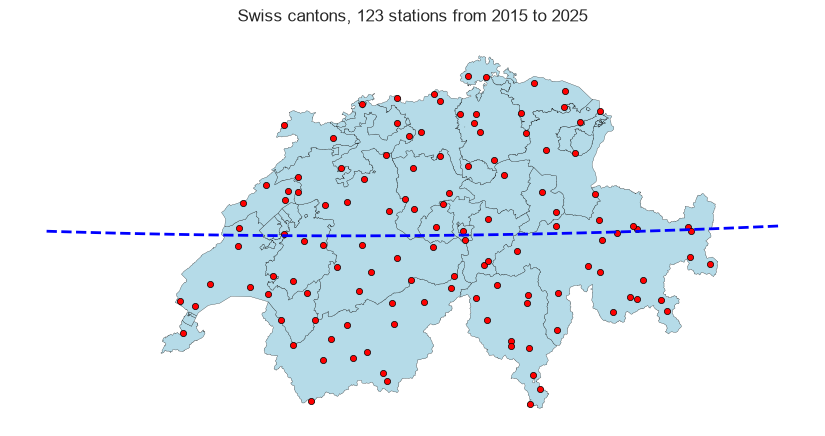

In [ ]:
import numpy as np
from shapely.geometry import LineString

stations_location_2 = df_stable_2015_2025[["station_abbr", "latitude", "longitude"]].drop_duplicates("station_abbr")

points = gpd.GeoDataFrame(
    stations_location_2,
    geometry=gpd.points_from_xy(stations_location_2["longitude"], stations_location_2["latitude"]),
    crs="EPSG:4326",  # coordonnées longitude/latitude
).to_crs(cantons.crs)  # même projection que la carte

ax = cantons.plot(
    column="name",          # une couleur par canton
    categorical=True,
    #cmap="blue",        # palette de couleurs
    color="lightblue",
    legend=True,
    figsize=(10, 20),
    edgecolor="black",      # couleur des limites
    linewidth=0.2,          # épaisseur des limites
    alpha=0.9,             # opacité
)

lat = 46.8
longitudes = np.linspace(5, 11, 200)  # traverse la Suisse

ligne_468 = gpd.GeoSeries(
    [LineString([(lon, lat) for lon in longitudes])],
    crs="EPSG:4326",
).to_crs(cantons.crs)

ligne_468.plot(ax=ax, color="blue", linewidth=2, linestyle="--")

points.plot(ax=ax, color="red", markersize=20, edgecolor="black")

ax.set_title("Swiss cantons, 123 stations from 2015 to 2025", fontsize=12, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

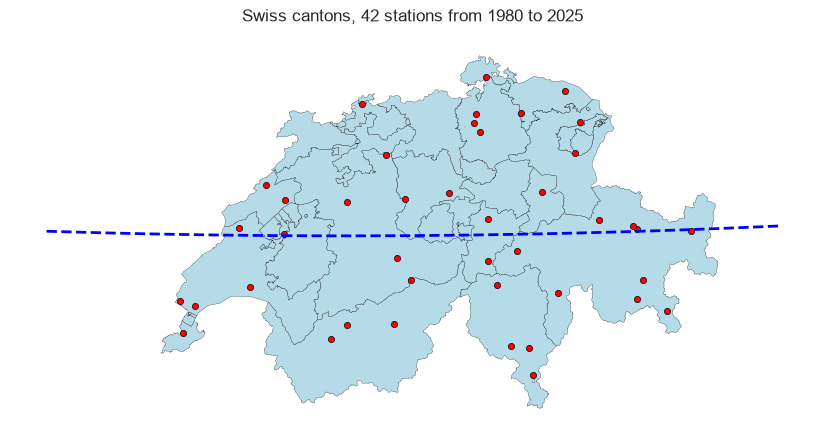

In [145]:
stations_location_1 = df_stable_1980_2025[["station_abbr", "latitude", "longitude"]].drop_duplicates("station_abbr")

points = gpd.GeoDataFrame(
    stations_location_1,
    geometry=gpd.points_from_xy(stations_location_1["longitude"], stations_location_1["latitude"]),
    crs="EPSG:4326",  # coordonnées longitude/latitude
).to_crs(cantons.crs)  # même projection que la carte

ax = cantons.plot(
    column="name",          # une couleur par canton
    categorical=True,
    #cmap="blue",        # palette de couleurs
    color="lightblue",
    legend=True,
    figsize=(10, 20),
    edgecolor="black",      # couleur des limites
    linewidth=0.2,          # épaisseur des limites
    alpha=0.9,             # opacité
)

lat = 46.8
longitudes = np.linspace(5, 11, 200)  # traverse la Suisse

ligne_468 = gpd.GeoSeries(
    [LineString([(lon, lat) for lon in longitudes])],
    crs="EPSG:4326",
).to_crs(cantons.crs)

ligne_468.plot(ax=ax, color="blue", linewidth=2, linestyle="--")

points.plot(ax=ax, color="red", markersize=20, edgecolor="black")

ax.set_title("Swiss cantons, 42 stations from 1980 to 2025", fontsize=12, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Merge two maps 

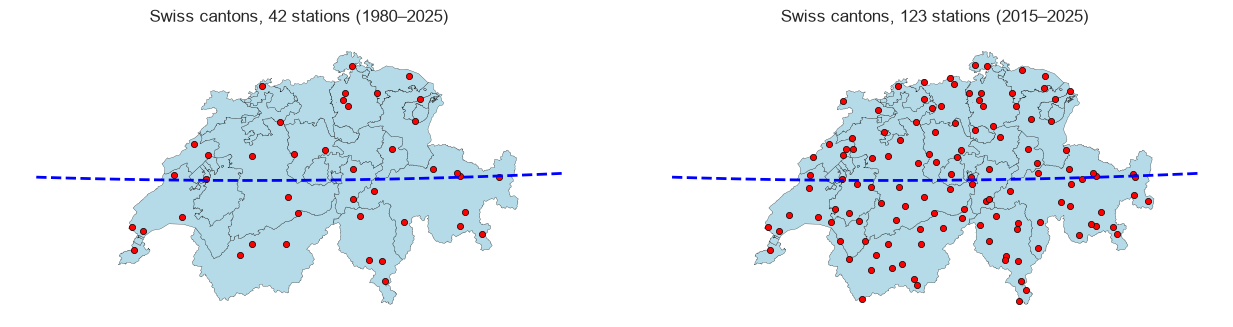

In [147]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import LineString


def creer_points(df):
    stations = (
        df[["station_abbr", "latitude", "longitude"]]
        .dropna(subset=["station_abbr", "latitude", "longitude"])
        .drop_duplicates(subset="station_abbr")
    )

    return gpd.GeoDataFrame(
        stations,
        geometry=gpd.points_from_xy(
            stations["longitude"],
            stations["latitude"],
        ),
        crs="EPSG:4326",
    ).to_crs(cantons.crs)


points_1980_2025 = creer_points(df_stable_1980_2025)
points_2015_2025 = creer_points(df_stable_2015_2025)

# Ligne de latitude 46,8°
lat = 46.8
longitudes = np.linspace(5, 11, 200)

ligne_468 = gpd.GeoSeries(
    [LineString([(lon, lat) for lon in longitudes])],
    crs="EPSG:4326",
).to_crs(cantons.crs)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

cartes = [
    (axes[0], points_1980_2025, "1980–2025"),
    (axes[1], points_2015_2025, "2015–2025"),
]

for ax, points, periode in cartes:
    cantons.plot(
        ax=ax,
        color="lightblue",
        edgecolor="black",
        linewidth=0.2,
        alpha=0.9,
    )

    ligne_468.plot(
        ax=ax,
        color="blue",
        linewidth=2,
        linestyle="--",
    )

    points.plot(
        ax=ax,
        color="red",
        markersize=20,
        edgecolor="black",
    )

    ax.set_title(
        f"Swiss cantons, {len(points)} stations ({periode})",
        fontsize=12,
        pad=12,
    )
    ax.set_axis_off()

plt.tight_layout()
plt.show()

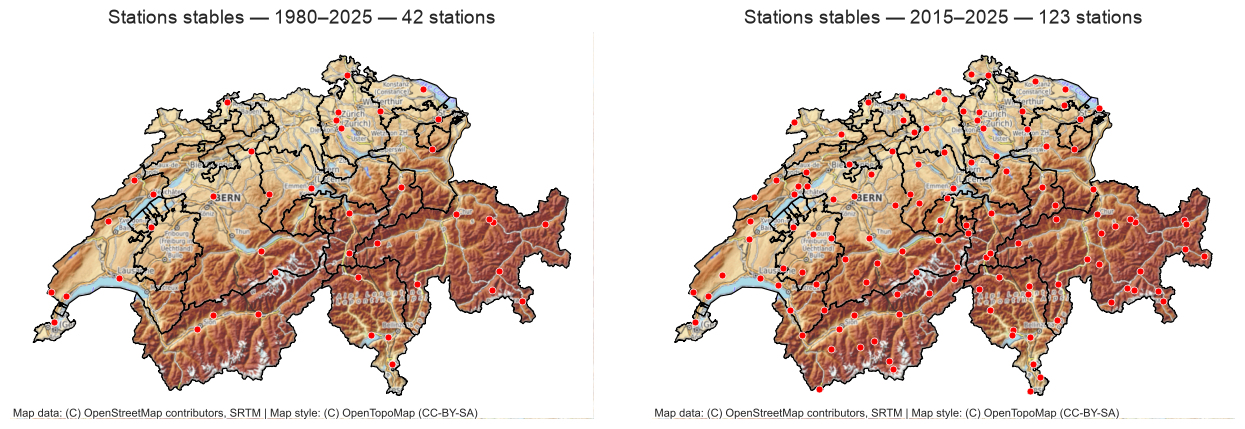

Stations représentées en 1980–2025 : 42
Stations représentées en 2015–2025 : 123


In [146]:
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


def creer_points(df):
    # Une ligne par station, avec des coordonnées valides
    stations = (
        df[["station_abbr", "latitude", "longitude"]]
        .dropna(subset=["station_abbr", "latitude", "longitude"])
        .drop_duplicates(subset="station_abbr")
    )

    return gpd.GeoDataFrame(
        stations,
        geometry=gpd.points_from_xy(stations["longitude"], stations["latitude"]),
        crs="EPSG:4326",
    ).to_crs(cantons.crs)


points_1980_2025 = creer_points(df_stable_1980_2025)
points_2015_2025 = creer_points(df_stable_2015_2025)

# Même emprise pour les deux cartes
xmin, ymin, xmax, ymax = cantons.total_bounds
marge = 15_000
xmin, ymin = xmin - marge, ymin - marge
xmax, ymax = xmax + marge, ymax + marge

suisse = cantons.geometry.union_all()
cadre = box(xmin, ymin, xmax, ymax)
masque = gpd.GeoSeries([cadre.difference(suisse)], crs=cantons.crs)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

cartes = [
    (axes[0], points_1980_2025, "Stations stables — 1980–2025"),
    (axes[1], points_2015_2025, "Stations stables — 2015–2025"),
]

for ax, points, titre in cartes:
    cantons.plot(
        ax=ax,
        facecolor="none",
        edgecolor="none",
    )

    cx.add_basemap(
        ax,
        source=cx.providers.OpenTopoMap,
        crs=cantons.crs,
        alpha=0.8,
    )

    # Masque blanc hors des frontières suisses
    masque.plot(ax=ax, color="white", edgecolor="none", zorder=2)

    # Frontières cantonales et stations
    cantons.boundary.plot(ax=ax, color="black", linewidth=0.8, zorder=3)
    points.plot(
        ax=ax,
        color="red",
        markersize=25,
        edgecolor="white",
        linewidth=0.5,
        zorder=4,
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{titre} — {len(points)} stations")
    ax.set_axis_off()

plt.tight_layout()
plt.show()

print("Stations représentées en 1980–2025 :", len(points_1980_2025))
print("Stations représentées en 2015–2025 :", len(points_2015_2025))

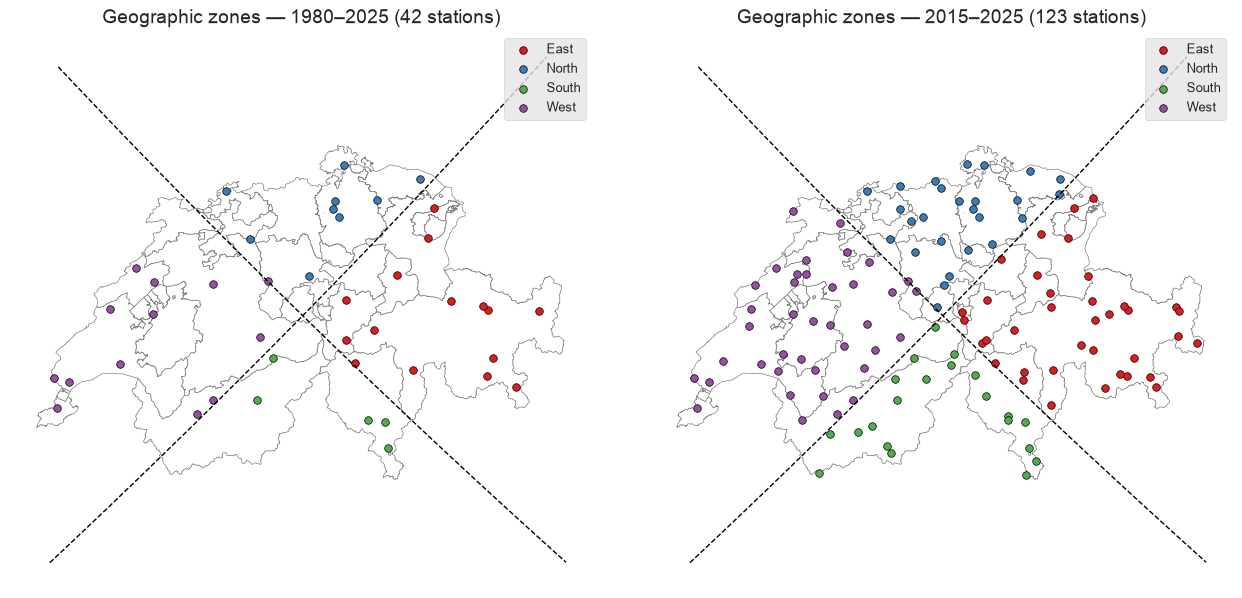

In [151]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import LineString

# Coordonnées de référence de toutes les stations
stations_reference = (
    df_all[["station_abbr", "latitude", "longitude"]]
    .dropna(subset=["station_abbr", "latitude", "longitude"])
    .drop_duplicates("station_abbr")
)

centre_lat = stations_reference["latitude"].mean()
centre_lon = stations_reference["longitude"].mean()
correction = np.cos(np.deg2rad(centre_lat))


def creer_points_par_zone(df):
    stations = (
        df[["station_abbr", "latitude", "longitude"]]
        .dropna(subset=["station_abbr", "latitude", "longitude"])
        .drop_duplicates("station_abbr")
        .copy()
    )

    dx = (
        (stations["longitude"] - centre_lon)
        * correction
    )
    dy = stations["latitude"] - centre_lat

    stations["geo_zone"] = np.select(
        [
            (dy >= 0) & (dy >= abs(dx)),
            (dy < 0) & (-dy >= abs(dx)),
            (dx < 0) & (abs(dx) > abs(dy)),
            (dx >= 0) & (dx > abs(dy)),
        ],
        ["North", "South", "West", "East"],
        default="East",
    )

    return gpd.GeoDataFrame(
        stations,
        geometry=gpd.points_from_xy(
            stations["longitude"],
            stations["latitude"],
        ),
        crs="EPSG:4326",
    ).to_crs(cantons.crs)


points_1980_2025 = creer_points_par_zone(df_stable_1980_2025)
points_2015_2025 = creer_points_par_zone(df_stable_2015_2025)

# Deux diagonales qui délimitent les zones géographiques
longitudes = np.linspace(
    stations_reference["longitude"].min() - 0.01,
    stations_reference["longitude"].max() + 0.01,
    200,
)

diagonales = gpd.GeoSeries(
    [
        LineString(
            zip(
                longitudes,
                centre_lat + correction * (longitudes - centre_lon),
            )
        ),
        LineString(
            zip(
                longitudes,
                centre_lat - correction * (longitudes - centre_lon),
            )
        ),
    ],
    crs="EPSG:4326",
).to_crs(cantons.crs)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

cartes = [
    (axes[0], points_1980_2025, "1980–2025"),
    (axes[1], points_2015_2025, "2015–2025"),
]

for ax, points, periode in cartes:
    cantons.plot(
        ax=ax,
        facecolor="white",
        edgecolor="gray",
        linewidth=0.5,
    )

    diagonales.plot(
        ax=ax,
        color="black",
        linestyle="--",
        linewidth=1,
    )

    points.plot(
        ax=ax,
        column="geo_zone",
        categorical=True,
        cmap="Set1",
        legend=True,
        markersize=30,
        edgecolor="black",
    )

    ax.set_title(
        f"Geographic zones — {periode} ({len(points)} stations)"
    )
    ax.set_axis_off()

plt.tight_layout()
plt.show()